# FW CADIS for weight window generation

In this notebook, we create (using a small companion library `mcbb` which handles data I/O) mgxs from an openmc simulation.
Then, we use the deterministic code to generate FW-CADIS based weight windows, after which we compare the figure of merit 
on the same geometry, showing O(10^2) improvement!

In [1]:
%load_ext autoreload
%autoreload 2
import jax.numpy as jnp
import jax_sn
import jax
import matplotlib.pyplot as plt
import numpy as onp
import equinox as eqx
jax.config.update("jax_enable_x64", True)
from functools import partial
import pyvista as pv

import lineax as lx
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver, MultiGroupOperatorScanCheckpoint
from jax_sn.solution_domain import SolutionDomainData, SolutionDomain, BasixLagrangianSimplex
from typing import Tuple, Callable, Iterable
from dataclasses import dataclass
from breeding_blanket_setup import _get_bb_args, _setup_bb_mgop_symmetric, aux_data_dict, bb_data_dict
import mcbb

We use a standard hcpb blanket from the mcbb package. 

This will also download some cross section data.

Creating a cross section data library is then simple:

In [3]:
hcpb_blanket = mcbb.examples.hcpb()
n_samples_per_batch =1e5
groups_list = [14.1e6, 1e6, 300, 10, 0]
n_x_tally = 200
settings = mcbb.blanket_base.OpenMCSettingsBlanket(True, "openmc_data/", 10, n_samples_per_batch , seed = 10)
simulation_symm = mcbb.linear_blanket.OpenMCSymmetricLinearBlanketSimulation(hcpb_blanket, settings, n_x_tally, groups_list)
mgxs_lib  = simulation_symm.create_mgxs_library(onp.flip(groups_list), 4)
openmc_data = mcbb.openmc_base_functions.mgxs_lib_to_data_dicts(mgxs_lib)

/home/tbogaarts/miniconda/envs/stellsim/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=411.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda/envs/stellsim/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=820.
  warn(msg, IDWarning)
/home/tbogaarts/miniconda/envs/stellsim/lib/python3.12/site-packages/openmc/mixin.py:70: IDWarning: Another Filter instance already exists with id=423.
  warn(msg, IDWarning)


We can plot the figure of merit (1/RE**2/T) as a function of the tally bin:

/home/tbogaarts/miniconda/envs/stellsim/lib/python3.12/site-packages/openmc/tallies.py:1859: RuntimeWarning: invalid value encountered in divide
  data = self.std_dev[indices] / self.mean[indices]


Text(0, 0.5, 'Figure of Merit')

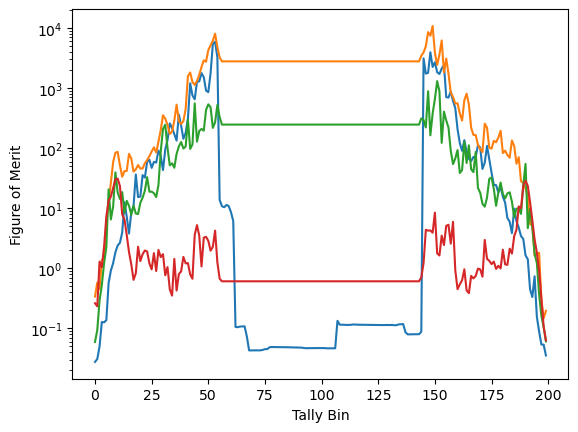

In [4]:
tally_result = simulation_symm.get_tally_results(quantities=['mean', 'rel_err'])

plt.semilogy(1 / (tally_result['flux']['rel_err']**2 * tally_result['runtime']))
plt.xlabel("Tally Bin")
plt.ylabel("Figure of Merit")

We then directly setup a linear blanket simulation using 10 elements in all blanket layers.

The Pallas version is significantly faster but not supported in all architectures.

In [5]:
from mcbb.sn.base_sn import setup_linear_symm_mgop
from jax_sn.operators.transport_operator.transport_operator_base import TransportOperatorVmapPallas, TransportOperatorVmap

degree = 3
mgop, source_int =setup_linear_symm_mgop(hcpb_blanket, openmc_data[0], [10 for i in range(8)], degree, 3, single_angle_transport_operator_cls = TransportOperatorVmap)
element = BasixLagrangianSimplex(degree, 1)

solution_domain = SolutionDomain.from_element_and_domain(element, mgop.domain)

solver    = lx.BiCGStab(1e-10, 1e-10, max_steps=200)

W0326 14:26:28.300006   24759 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.
W0326 14:26:28.303402   24295 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.


Using `mcbb`, the weight windows can be directly generated. It interpolates the solution on 20 points:

Text(0, 0.5, 'Weight Window Bounds')

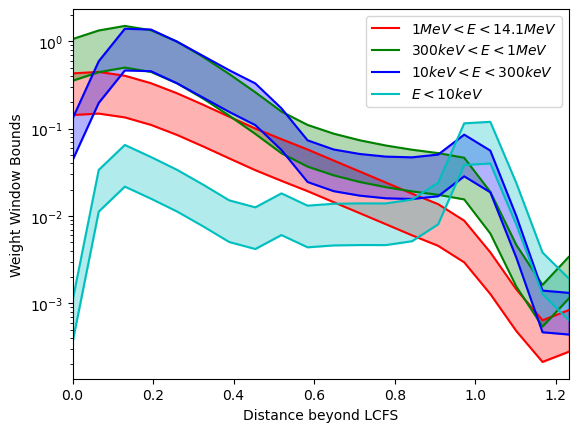

In [ ]:
from mcbb.sn.base_sn import create_importance_map_for_blanket, 
from mcbb.openmc_base_functions import _importance_map_to_weight_windows
d, importance_map = create_importance_map_for_blanket(hcpb_blanket, openmc_data[0], [10 for i in range(8)], degree, 3, n_weight_windows_in_blanket=20, single_angle_transport_operator_cls = TransportOperatorVmap)


# Just for plotting; we give directly the importance map later.
ww_up, ww_down = _importance_map_to_weight_windows(importance_map, ww_lower_upper_ratio = 3)
colors = ['r','g','b','c']
energy_groups = ['$1 MeV < E < 14.1 MeV$', '$300 keV < E < 1 MeV$', '$10 keV < E < 300 keV$', '$E < 10 keV$']
for i in range(ww_up.shape[0]):
    plt.plot(d, ww_up[i, :], color=colors[i], label=energy_groups[i])
    plt.plot(d, ww_down[i, :], color=colors[i], linestyle='-')
    plt.fill_between(d,  ww_up[i, :], ww_down[i, :], color=colors[i], alpha=0.3)
plt.yscale('log')
plt.legend()
plt.xlim(0, hcpb_blanket.average_thickness)
plt.xlabel("Distance beyond LCFS")
plt.ylabel("Weight Window Bounds")

This is of course rather similar to the scalar flux itself in this simple application.

We then map it to a 1D mesh of the right blanket (it's a symmetric linear simulation to not lose half of the neutrons to the void; reflective boundary in the middle is the same but reflective boundaries are not yet implemented in jax_sn)

In [7]:
from mcbb.openmc_base_functions import importance_map_to_weight_window

import openmc

importance_map_elem = 0.5 * (importance_map[:, :-1] + importance_map[:, 1:])
thickness_base=  sum([layer.thickness for layer in hcpb_blanket.layers])

thickness_edge = thickness_base + sum([layer.thickness for layer in hcpb_blanket.layers][1:])
nodes = onp.linspace(thickness_base, thickness_edge, importance_map.shape[1])

mesh = openmc.RectilinearMesh()

mesh.x_grid = nodes * 1e2 -123.2
mesh.y_grid = [-10000.0, 10000.0]
mesh.z_grid = [-10000.0, 10000.0]

weight_windows = importance_map_to_weight_window(importance_map_elem, groups_list, mesh, max_split = 2000)

We generate the same simulation but with a weight window and run it. It will take slightly longer due to the weight windows splitting particles.

In [8]:
sim_2 = simulation_symm.with_weight_windows(weight_windows)

sim_2.run(statepoint_file = "statepoint.10_ww.h5")



'statepoint.10_ww.h5'

We can now compare both figures of merit, showing $O(10^2)$ increase with weight windows!

/home/tbogaarts/miniconda/envs/stellsim/lib/python3.12/site-packages/openmc/tallies.py:1859: RuntimeWarning: invalid value encountered in divide
  data = self.std_dev[indices] / self.mean[indices]


Text(0, 0.5, 'Figure of Merit')

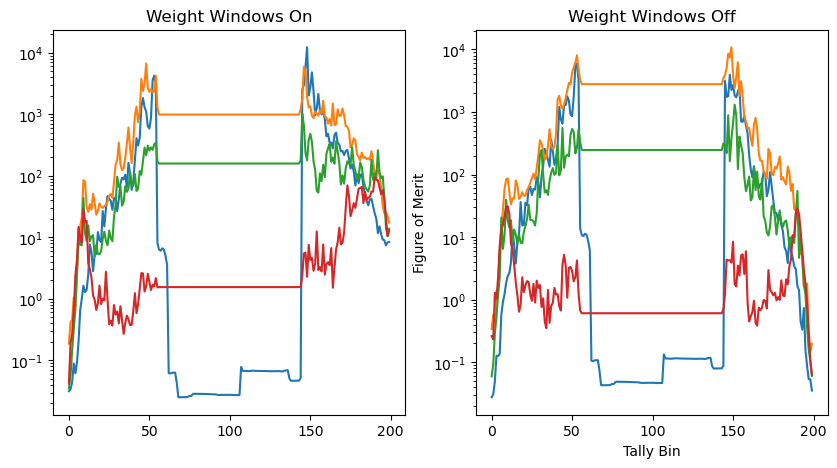

In [11]:
tally_result_ww = sim_2.get_tally_results(quantities=['mean', 'rel_err'])
fig, axs = plt.subplots(1,2, figsize = (10,5))

axs[0].set_title("Weight Windows On")
axs[0].semilogy(1 / (tally_result_ww['flux']['rel_err']**2 * tally_result_ww['runtime']))#, label="WW On")

axs[1].set_title("Weight Windows Off")
axs[1].semilogy(1 / (tally_result['flux']['rel_err']**2 * tally_result['runtime']))#, label = "WW Off")

plt.xlabel("Tally Bin")
plt.ylabel("Figure of Merit")

